# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?
- ¿Qué representa en el caso del filtro de promedio móvil?

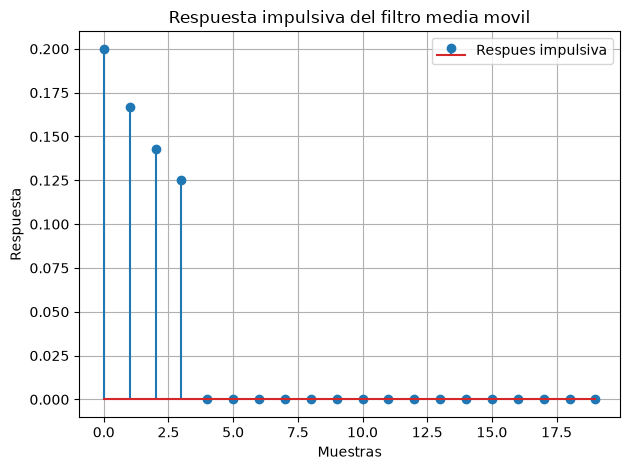

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(func, window):
    average = np.zeros(len(func))                           # Media con todos ceros
    for n in range (len(func)):                             # Itera para completar el rango de la media
        suma = 0
        division = 0
        for k in range (-window, window):                   # Itera en la ventana indicada
            if ((n - k) >= 0) and ((n - k) < len(func)):    # Se verifica que no se salga del rango de la función
                suma = suma + func[(n - k)]
                division = division + 1
        average[n] = suma / division
    return average

N = 20
impulso = np.zeros(N)
impulso[0] = 1

respuesta_impulsiva = moving_average(impulso, 4)

plt.stem(respuesta_impulsiva, label='Respues impulsiva')
plt.legend()
plt.grid(True)
plt.title("Respuesta impulsiva del filtro media movil")
plt.ylabel("Respuesta")
plt.xlabel("Muestras")
plt.tight_layout()
plt.show()

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?

Se implementa aplicando como señal de entrada la delta de Dirac

- ¿Qué representa en el caso del filtro de promedio móvil?

En cualquier caso nos indicará como responderá el sistema frente a una señal de entrada. En este caso especifico con una ventana de 4 valores nos indicará los coeficientes por los que se multiplicará una señal de entrada, con una memoria de 4 valores.

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?


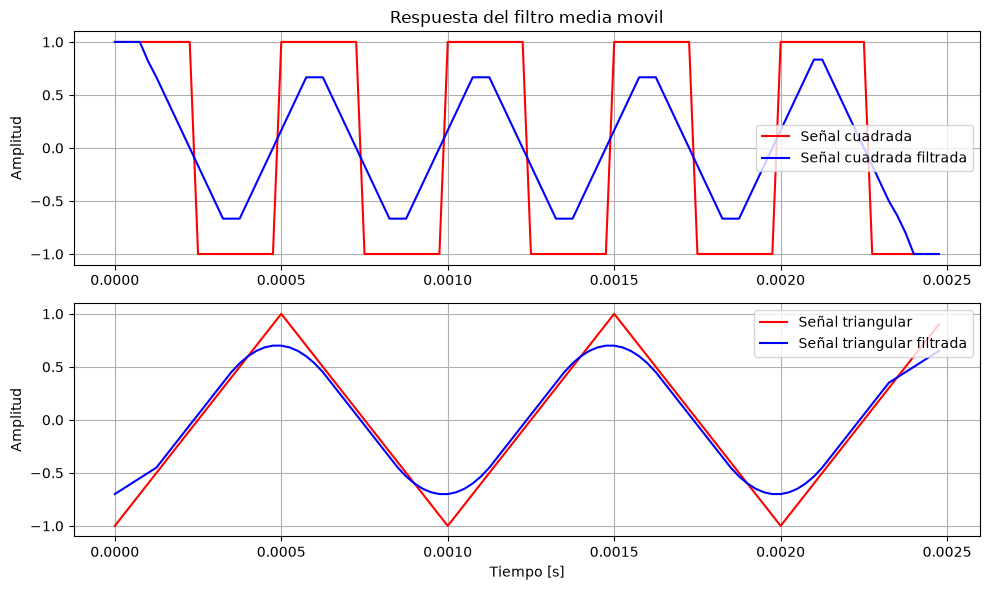

In [3]:
def square_wave(N, fs, A, f):
    square = np.zeros(N)
    T = 1 / f
    for n in range(N):
        t = n / fs
        if (t % T) < (T / 2):
            square[n] = A
        else:
            square[n] = -A
    return square

def triangle_wave(N, fs, A, f):
    triangle = np.zeros(N)
    T = 1 / f
    pendiente = 2 * A / (T / 2)
    for n in range(N):
        t = n / fs
        if (t % T) < (T / 2):
            triangle[n] = -A + pendiente * (t % T)
        else:
            triangle[n] = A - pendiente * ((t % T) - T / 2)
    return triangle

window = 6
N = 100
fs = 40000
A = 1
f1 = 2000
f2 = 1000
t = np.arange(0, N / fs, 1 / fs)

square = square_wave(N, fs, A, f1)
triangle = triangle_wave(N, fs, A, f2)

square_moving_average = moving_average(square, window)
triangle_moving_average = moving_average(triangle, window)

plt.figure(figsize=(10, 6))
plt.subplot(2,1,1)
plt.title("Respuesta del filtro media movil")
plt.plot(t, square, label='Señal cuadrada', color='red')
plt.plot(t, square_moving_average, label='Señal cuadrada filtrada', color='blue')
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t, triangle, label='Señal triangular', color='red')
plt.plot(t, triangle_moving_average, label='Señal triangular filtrada', color='blue')
plt.legend()
plt.grid(True)
plt.ylabel("Amplitud")
plt.xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

- ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?

Podemos darnos cuenta de dos efectos:
- Retraso en la señal: se puede observar, más facilmente en la señal triangular, como las señales filtradas por el filtro media movil se atrasan respecto a la señal de entrada.
- Filtrado de la señal: el filtro media movil se comporta como un filtro pasa bajos, ambas señales, cuadrada y triangular, tienden a una forma senoidal, eliminando armonicos de alta frecuencia.

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando la funcion fijo() de ejemplo.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficar todas las señales calculadas

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?
    - ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

--- TIEMPOS DE EJECUCIÓN (Promedio de 20 iteraciones) ---
NumPy (np.convolve):   0.0326 ms
Flotante (Custom):     40.86 ms
Punto Fijo (Custom):   255.13 ms

--- ERROR ABSOLUTO MEDIO (Respecto a NumPy) ---
Error Flotante:        5.72e-18
Error Punto Fijo:      8.33e-05


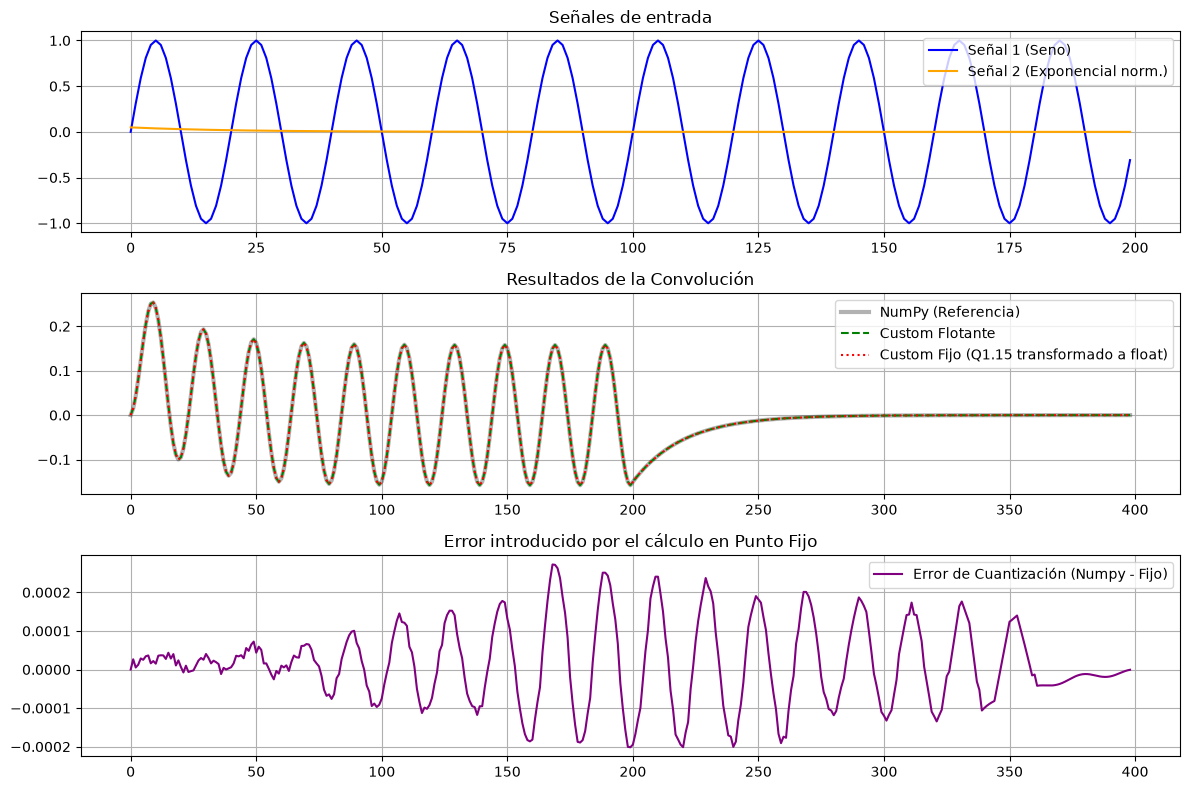

In [6]:
import timeit

def convolucion_flotante(func1, func2):
    N = len(func1)
    M = len(func2)
    conv = np.zeros(N + M - 1)
    for n in range (N + M - 1):
        suma = 0.0
        for k in range (N):
            if M > (n - k) >= 0:
                suma = suma + func1[k] * func2[n - k]
        conv[n] = suma
    return conv

def convolucion_fijo(func1, func2, frac_bits=15):
    N = len(func1)
    M = len(func2)
    conv = np.zeros(N + M - 1, dtype=np.int16)
    for n in range (N + M - 1):
        suma = np.int64(0)
        for k in range (N):
            if M > (n - k) >= 0:
                suma = suma + np.int64(func1[k]) * np.int64(func2[n - k])
        valor = suma >> frac_bits
        conv[n] = np.clip(valor, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)
    return conv

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

N_muestras = 200
n = np.arange(N_muestras)

func1 = np.sin(2 * np.pi * 0.05 * n)  
func2 = np.exp(-0.05 * n)
func2 = func2 / np.sum(func2)  

func1_fijo = fijo(func1)
func2_fijo = fijo(func2)

iters = 20

t_float = timeit.timeit(lambda: convolucion_flotante(func1, func2), number=iters)
conv_float = convolucion_flotante(func1, func2)

t_fijo = timeit.timeit(lambda: convolucion_fijo(func1_fijo, func2_fijo), number=iters)
conv_fijo_int = convolucion_fijo(func1_fijo, func2_fijo)
conv_fijo_float = conv_fijo_int / (1 << 15) # Paso a float

t_np = timeit.timeit(lambda: np.convolve(func1, func2), number=iters)
conv_np = np.convolve(func1, func2)

# Errores respecto a numpy
error_float = np.mean(np.abs(conv_float - conv_np))
error_fijo = np.mean(np.abs(conv_fijo_float - conv_np))

print(f"--- TIEMPOS DE EJECUCIÓN (Promedio de {iters} iteraciones) ---")
print(f"NumPy (np.convolve):   {t_np/iters * 1000:.4f} ms")
print(f"Flotante (Custom):     {t_float/iters * 1000:.2f} ms")
print(f"Punto Fijo (Custom):   {t_fijo/iters * 1000:.2f} ms")
print(f"\n--- ERROR ABSOLUTO MEDIO (Respecto a NumPy) ---")
print(f"Error Flotante:        {error_float:.2e}")
print(f"Error Punto Fijo:      {error_fijo:.2e}")

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(func1, label='Señal 1 (Seno)', color='blue')
plt.plot(func2, label='Señal 2 (Exponencial norm.)', color='orange')
plt.title('Señales de entrada')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(conv_np, label='NumPy (Referencia)', color='black', linewidth=3, alpha=0.3)
plt.plot(conv_float, label='Custom Flotante', color='green', linestyle='--')
plt.plot(conv_fijo_float, label='Custom Fijo (Q1.15 transformado a float)', color='red', linestyle=':')
plt.title('Resultados de la Convolución')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(conv_np - conv_fijo_float, label='Error de Cuantización (Numpy - Fijo)', color='purple')
plt.title('Error introducido por el cálculo en Punto Fijo')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

- ¿Qué diferencias observas entre las implementaciones?

La mayor diferencia, en este caso al utilizar python, es tener que implementar funciones de fijado de tipo, como en este caso enteros, ya que de caso contrario los tomaría como flotantes, todo este proceso de conversiones conlleva tiempo de ejecución, razón por la cual su tiempo de ejecución es mayor.

- ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

En este caso la implementación en python demoró más de lo esperado, en un microcontrolador el tiempo de ejecución con enteros debería ser menor al del flotante (siempre y cuando su hardware no incluya FPU), por lo que el error cometido sería aceptable frente al rendimiento.

In [16]:
# Ejemplos de medicion de tiempos
# %pylab inline
import timeit
import time
import numpy as np

t = np.arange(0, 1024/20000, 1/20000)
s1= np.sin(2*np.pi*1000*t)+1
s2 = np.sin(2*np.pi*1200*t)

# METODO 1 de medición de tiempos

# Este wrapper empaqueta funciones para que el timeit pueda medir solo eso
def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

conv = wrapper(np.convolve, s1, s2)
print (timeit.timeit(conv, number=1))

# METODO 2 de medición de tiempos
start = time.time()
conv_r = np.convolve(s1,s2)
end = time.time()
print (end-start)

0.0011830409994217916
0.001291513442993164


Float => Max: 1.0, Min: -1.0
Fijo => Max: 32767, Min: -32768


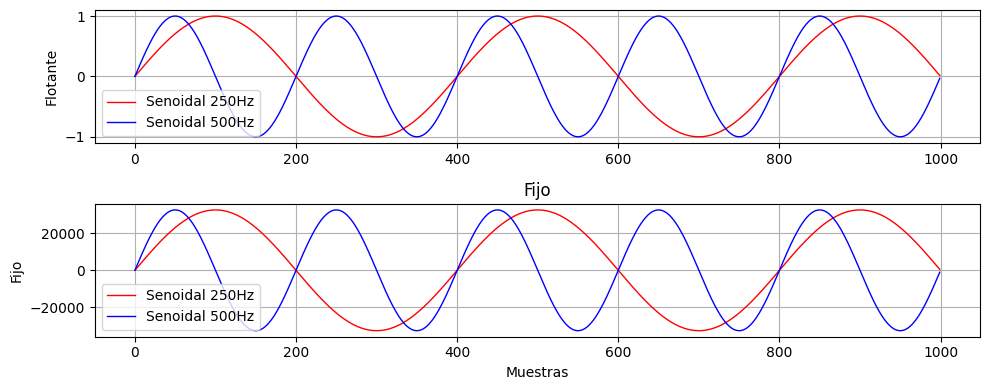

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

fs = 100000      # Frecuencia de muestreo
N = 1000        # Duración total
t = np.arange(0,N/fs,1/fs)

f1 = 250
f2 = 500

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

x = np.sin(2*np.pi*f1*t)
y = np.sin(2*np.pi*f2*t)

xf = fijo(x)
yf = fijo(y)

print(f"Float => Max: {max(x)}, Min: {min(x)}")
print(f"Fijo => Max: {max(xf)}, Min: {min(xf)}")

plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(t*fs, x, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, y, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.ylabel("Flotante")
plt.legend()
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t*fs, xf, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, yf, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.legend()
plt.grid(True)
plt.title("Fijo")
plt.ylabel("Fijo")
plt.xlabel("Muestras")
plt.tight_layout()
plt.show()